# Predicting pathological complete response before surgery: internal accuracy against an
# independent cohort

**Data:** two public neoadjuvant breast-cancer cohorts profiled on the same array (Affymetrix
HG-U133A, GPL96), so expression values are directly comparable.

* **GSE25066** --- 508 patients, taxane/anthracycline neoadjuvant therapy, pCR or residual disease
  recorded, with ER/PR/HER2 status, grade, clinical T and N stage and age.
* **GSE20194** --- 278 patients from the MAQC-II breast cancer study, same endpoint and the same
  clinical variables.

**Questions**
1. How well can pathological complete response (pCR) be predicted before surgery?
2. How much of that is simply **ER status**? pCR is far more common in ER-negative disease, so a
   predictor that only recovers receptor status adds nothing a pathologist does not already have.
3. Does cross-validated accuracy within one cohort survive **transfer to a genuinely independent
   cohort**, recruited and processed elsewhere?
4. How much does the cross-cohort normalisation choice change the answer?

Runs in Colab or Kaggle. Downloads ~80 MB from NCBI GEO on first run.

In [1]:
import os, sys, gzip, json, time, warnings, subprocess, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 300})
SEED = 42
ON_KAGGLE = os.path.isdir("/kaggle/working")
BASE = "/kaggle/working" if ON_KAGGLE else "."
FIG, RES = f"{BASE}/figures", f"{BASE}/results"
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
N_TOP_VAR = 3000
N_REP = 5
CTRAIN, CTEST = "GSE25066", "GSE20194"
COL = {"Clinical only": "#1F5F8B", "Expression only": "#C2185B", "Clinical + expression": "#2E7D32",
       "ER status alone": "#78909C"}

GEO = {"GSE25066": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE25nnn/GSE25066/matrix/GSE25066_series_matrix.txt.gz",
       "GSE20194": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE20nnn/GSE20194/matrix/GSE20194_series_matrix.txt.gz"}

## 1. Load the two series matrices

In [2]:
def locate(acc):
    for p in (f"/kaggle/input/neoadjuvant-brca-geo/{acc}.txt.gz", f"data/{acc}.txt.gz", f"{acc}.txt.gz"):
        if os.path.exists(p):
            return p
    import glob
    hits = glob.glob(f"/kaggle/input/**/{acc}.txt.gz", recursive=True)
    if hits:
        return hits[0]
    os.makedirs("data", exist_ok=True)
    print(f"  downloading {acc} from GEO ...", flush=True)
    urllib.request.urlretrieve(GEO[acc], f"data/{acc}.txt.gz")
    return f"data/{acc}.txt.gz"


def read_series_matrix(path):
    """Return (expression DataFrame probes x samples, characteristics DataFrame samples x fields)."""
    chars, gsm = [], None
    with gzip.open(path, "rt") as fh:
        for line in fh:
            if line.startswith("!Sample_geo_accession"):
                gsm = [v.strip('"') for v in line.rstrip("\n").split("\t")[1:]]
            elif line.startswith("!Sample_characteristics_ch1"):
                chars.append([v.strip('"') for v in line.rstrip("\n").split("\t")[1:]])
            elif line.startswith("!series_matrix_table_begin"):
                break
        expr = pd.read_csv(fh, sep="\t", index_col=0, comment="!", low_memory=False)
    expr.columns = [c.strip('"') for c in expr.columns]
    expr.index = [str(i).strip('"') for i in expr.index]
    meta = {}
    for row in chars:
        for s, cell in zip(gsm, row):
            if ":" in cell:
                k, v = cell.split(":", 1)
                meta.setdefault(k.strip().lower(), {})[s] = v.strip()
    return expr, pd.DataFrame(meta).reindex(gsm)


t0 = time.time()
raw = {}
for acc in (CTRAIN, CTEST):
    e, m = read_series_matrix(locate(acc))
    raw[acc] = (e, m)
    print(f"{acc}: {e.shape[0]:,} probes x {e.shape[1]} samples | {m.shape[1]} annotation fields "
          f"({time.time()-t0:.0f}s)")

GSE25066: 22,283 probes x 508 samples | 25 annotation fields (1s)


GSE20194: 22,283 probes x 278 samples | 16 annotation fields (1s)


## 2. Harmonise the two cohorts
The two studies label the same clinical variables differently, so they are mapped onto a common
schema. Only variables available in both are retained, so the clinical model is identical across
cohorts.

In [3]:
FIELDS = {
    CTRAIN: {"pcr": "pathologic_response_pcr_rd", "er": "er_status_ihc", "pr": "pr_status_ihc",
             "her2": "her2_status", "grade": "grade", "t": "clinical_t_stage",
             "n": "clinical_nodal_status", "age": "age_years"},
    CTEST: {"pcr": "pcr_vs_rd", "er": "er_status", "pr": "pr_status", "her2": "her2 status",
            "grade": "bmngrd", "t": "tbefore", "n": "nbefore", "age": "age"},
}

def pos_neg(v):
    v = str(v).strip().upper()
    return 1.0 if v in ("P", "POS", "POSITIVE", "1") else (0.0 if v in ("N", "NEG", "NEGATIVE", "0") else np.nan)

def num(v):
    try:
        f = float(str(v).strip())
        return f if np.isfinite(f) else np.nan
    except Exception:
        return np.nan

def tstage(v):
    s = str(v).strip().upper().replace("T", "")
    return num(s[0]) if s[:1].isdigit() else np.nan

def grade(v):
    g = num(str(v).split("=")[0])
    return g if g in (1, 2, 3) else np.nan      # '4=Indeterminate' becomes missing

clin, y, expr = {}, {}, {}
for acc in (CTRAIN, CTEST):
    e, m = raw[acc]; f = FIELDS[acc]
    lab = m[f["pcr"]].astype(str).str.strip().str.upper()
    keep = lab.isin(["PCR", "RD"])
    d = pd.DataFrame({
        "ER": m.loc[keep, f["er"]].map(pos_neg),
        "PR": m.loc[keep, f["pr"]].map(pos_neg),
        "HER2": m.loc[keep, f["her2"]].map(pos_neg),
        "grade": m.loc[keep, f["grade"]].map(grade),
        "T": m.loc[keep, f["t"]].map(tstage),
        "N": m.loc[keep, f["n"]].map(lambda v: tstage(str(v).replace("N", ""))),
        "age": m.loc[keep, f["age"]].map(num)}, index=m.index[keep])
    clin[acc] = d
    y[acc] = (lab[keep] == "PCR").astype(int).values
    expr[acc] = e[d.index]
    print(f"{acc}: {len(d)} patients, {y[acc].sum()} pCR ({100*y[acc].mean():.1f}%), "
          f"missing clinical {100*d.isna().mean().mean():.1f}%")

probes = expr[CTRAIN].index.intersection(expr[CTEST].index)
for acc in (CTRAIN, CTEST):
    expr[acc] = expr[acc].loc[probes]
print(f"\nshared probes: {len(probes):,} (same platform, GPL96)")

GSE25066: 488 patients, 99 pCR (20.3%), missing clinical 1.9%
GSE20194: 278 patients, 56 pCR (20.1%), missing clinical 0.8%

shared probes: 22,283 (same platform, GPL96)


In [4]:
rows = []
for acc in (CTRAIN, CTEST):
    d, yy = clin[acc], y[acc]
    rows.append({"Cohort": acc, "Patients": len(d), "pCR n (%)": f"{yy.sum()} ({100*yy.mean():.0f}%)",
                 "ER-positive": f"{int(d.ER.sum())} ({100*d.ER.mean():.0f}%)",
                 "HER2-positive": f"{int(d.HER2.sum())} ({100*d.HER2.mean():.0f}%)",
                 "Grade 3": f"{int((d.grade == 3).sum())} ({100*(d.grade == 3).mean():.0f}%)",
                 "Age median [IQR]": f"{d.age.median():.0f} [{d.age.quantile(.25):.0f}-{d.age.quantile(.75):.0f}]",
                 "pCR in ER-neg": f"{100*yy[d.ER.eq(0).values].mean():.0f}%",
                 "pCR in ER-pos": f"{100*yy[d.ER.eq(1).values].mean():.0f}%"})
table1 = pd.DataFrame(rows).set_index("Cohort").T
table1.to_csv(f"{RES}/Table1_cohorts.csv")
table1

Cohort,GSE25066,GSE20194
Patients,488,278
pCR n (%),99 (20%),56 (20%)
ER-positive,285 (59%),164 (59%)
HER2-positive,5 (1%),59 (21%)
Grade 3,252 (52%),150 (54%)
Age median [IQR],49 [42-58],51 [45-59]
pCR in ER-neg,35%,40%
pCR in ER-pos,11%,6%


## 3. pCR is strongly tied to receptor status
Before any model, the single clinical fact that dominates this endpoint.

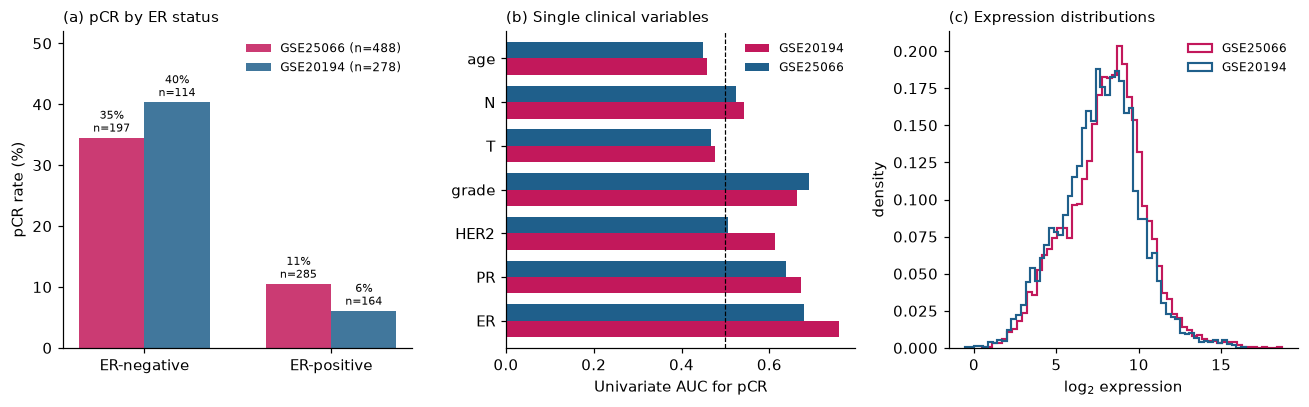

Cohort,GSE20194,GSE25066
Variable,,
ER,0.758,0.679
PR,0.672,0.639
HER2,0.613,0.507
grade,0.662,0.689
T,0.476,0.467
N,0.543,0.523
age,0.458,0.449


In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
ax = axs[0]
w = 0.35; x = np.arange(2)
for j, acc in enumerate((CTRAIN, CTEST)):
    d, yy = clin[acc], y[acc]
    vals = [100*yy[d.ER.eq(v).values].mean() for v in (0, 1)]
    ns = [int(d.ER.eq(v).sum()) for v in (0, 1)]
    b = ax.bar(x + (j-0.5)*w, vals, w, label=f"{acc} (n={len(d)})",
               color=["#C2185B", "#1F5F8B"][j], alpha=.85)
    for xi, v, n in zip(x + (j-0.5)*w, vals, ns):
        ax.text(xi, v + 1, f"{v:.0f}%\nn={n}", ha="center", fontsize=7)
ax.set_xticks(x, ["ER-negative", "ER-positive"]); ax.set_ylabel("pCR rate (%)")
ax.legend(fontsize=8, frameon=False); ax.set_ylim(0, 52)
ax.set_title("(a) pCR by ER status", fontsize=9.5, loc="left")

ax = axs[1]
tbl = []
for acc in (CTRAIN, CTEST):
    d, yy = clin[acc], y[acc]
    for v in ["ER", "PR", "HER2", "grade", "T", "N", "age"]:
        s = d[v]
        ok = s.notna().values
        if s.dropna().nunique() <= 2:
            a = yy[ok & s.eq(1).values].mean() if (ok & s.eq(1).values).sum() else np.nan
            b_ = yy[ok & s.eq(0).values].mean() if (ok & s.eq(0).values).sum() else np.nan
            p = stats.fisher_exact(pd.crosstab(s[ok], yy[ok]))[1] if s[ok].nunique() == 2 else np.nan
            eff = a - b_
        else:
            p = stats.mannwhitneyu(s[ok][yy[ok] == 1], s[ok][yy[ok] == 0]).pvalue
            eff = s[ok][yy[ok] == 1].mean() - s[ok][yy[ok] == 0].mean()
        tbl.append({"Cohort": acc, "Variable": v, "Effect (pCR − RD)": eff, "p": p,
                    "AUC": roc_auc_score(yy[ok], -s[ok]) if v in ("ER", "PR") else roc_auc_score(yy[ok], s[ok])})
uni = pd.DataFrame(tbl)
uni.to_csv(f"{RES}/Table2_univariate_clinical.csv", index=False)
piv = uni.pivot(index="Variable", columns="Cohort", values="AUC").loc[["ER", "PR", "HER2", "grade", "T", "N", "age"]]
piv.plot.barh(ax=ax, color=["#C2185B", "#1F5F8B"], width=.75, legend=True)
ax.axvline(.5, color="k", ls="--", lw=.8); ax.set_xlabel("Univariate AUC for pCR")
ax.legend(fontsize=8, frameon=False); ax.set_ylabel("")
ax.set_title("(b) Single clinical variables", fontsize=9.5, loc="left")

ax = axs[2]
for acc, c in ((CTRAIN, "#C2185B"), (CTEST, "#1F5F8B")):
    v = expr[acc].loc[probes].values.ravel()[::997]
    ax.hist(v, bins=60, histtype="step", density=True, color=c, label=acc, lw=1.4)
ax.set_xlabel("log$_2$ expression"); ax.set_ylabel("density")
ax.legend(fontsize=8, frameon=False)
ax.set_title("(c) Expression distributions", fontsize=9.5, loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig1_cohorts.png"); plt.show()
piv.round(3)

## 3b. The two cohorts overlap
GSE25066 (Hatzis et al.) assembled patients from several neoadjuvant trials, among them the MD
Anderson series that also makes up GSE20194 (MAQC-II). Before treating one as an independent test
set for the other, the obvious check is whether the arrays are the same arrays. Each test sample
is correlated against every training sample across all 22,283 shared probes.

test samples matching a training sample at r > 0.99: 187 of 278 (67%)
median max-correlation 0.999; independent samples remaining: 91
pCR rate: duplicated 0.17 | independent 0.27


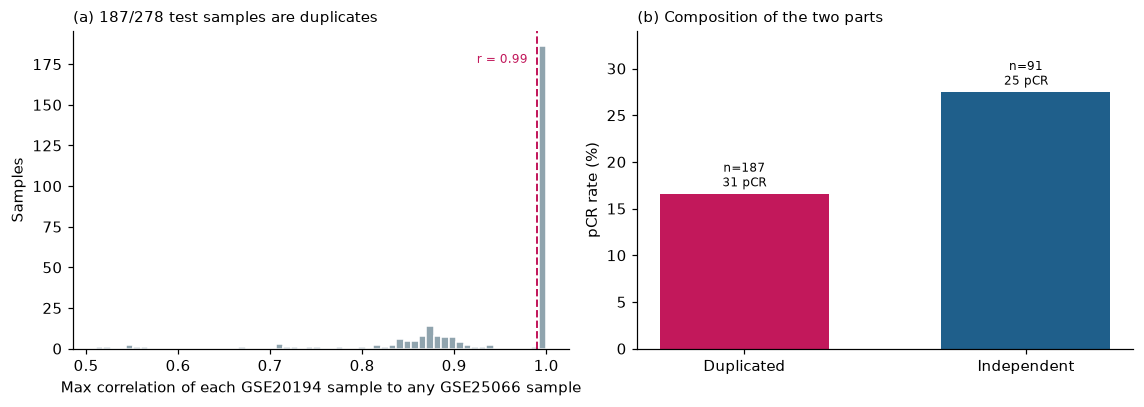

In [6]:
A = expr[CTRAIN].loc[probes].values.astype(np.float32)
B = expr[CTEST].loc[probes].values.astype(np.float32)
A = (A - A.mean(0)) / np.where(A.std(0) == 0, 1, A.std(0))
B = (B - B.mean(0)) / np.where(B.std(0) == 0, 1, B.std(0))
maxcor = ((B.T @ A) / A.shape[0]).max(axis=1)
DUP_T = 0.99
is_dup = maxcor > DUP_T
print(f"test samples matching a training sample at r > {DUP_T}: {int(is_dup.sum())} of {len(is_dup)} "
      f"({100*is_dup.mean():.0f}%)")
print(f"median max-correlation {np.median(maxcor):.3f}; independent samples remaining: {int((~is_dup).sum())}")
print(f"pCR rate: duplicated {y[CTEST][is_dup].mean():.2f} | independent {y[CTEST][~is_dup].mean():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axs[0]
ax.hist(maxcor, bins=60, color="#90A4AE", edgecolor="w")
ax.axvline(DUP_T, color="#C2185B", ls="--", lw=1.3)
ax.text(DUP_T - .01, ax.get_ylim()[1]*.9, f"r = {DUP_T}", ha="right", fontsize=8, color="#C2185B")
ax.set_xlabel(f"Max correlation of each {CTEST} sample to any {CTRAIN} sample")
ax.set_ylabel("Samples")
ax.set_title(f"(a) {int(is_dup.sum())}/{len(is_dup)} test samples are duplicates", fontsize=9.5, loc="left")
ax = axs[1]
ax.bar(["Duplicated", "Independent"], [100*y[CTEST][is_dup].mean(), 100*y[CTEST][~is_dup].mean()],
       color=["#C2185B", "#1F5F8B"], width=.6)
for i, (m, lbl) in enumerate(((is_dup, "Duplicated"), (~is_dup, "Independent"))):
    ax.text(i, 100*y[CTEST][m].mean() + .8, f"n={int(m.sum())}\n{int(y[CTEST][m].sum())} pCR",
            ha="center", fontsize=8)
ax.set_ylabel("pCR rate (%)"); ax.set_ylim(0, 34)
ax.set_title("(b) Composition of the two parts", fontsize=9.5, loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig2_cohort_overlap.png"); plt.show()

IND = ~is_dup                       # the genuinely independent subset of the test cohort
pd.DataFrame({"max_correlation_to_train": maxcor, "duplicate": is_dup,
              "pCR": y[CTEST]}, index=clin[CTEST].index).to_csv(f"{RES}/Table3_overlap.csv")

## 4. Feature matrices
Two normalisation strategies are compared, because the choice is consequential and often
unreported:

* **Train-fitted scaling** --- means and standard deviations estimated on the training cohort and
  applied unchanged to the test cohort. Honest, but exposed to any shift between studies.
* **Per-cohort z-scoring** --- each cohort standardised against its own distribution. Common
  practice for cross-study prediction, but it uses the test cohort's marginal distribution, so it
  is not available for a single incoming patient.

In [7]:
var_rank = expr[CTRAIN].var(axis=1).sort_values(ascending=False)
panel = list(var_rank.head(N_TOP_VAR).index)
CLIN_COLS = ["ER", "PR", "HER2", "grade", "T", "N", "age"]

def matrices(scheme):
    out = {}
    for acc in (CTRAIN, CTEST):
        E = expr[acc].loc[panel].T.astype(np.float32)
        if scheme == "per-cohort z":
            E = (E - E.mean()) / E.std().replace(0, 1)
        out[acc] = E
    if scheme == "train-fitted":
        mu, sd = out[CTRAIN].mean(), out[CTRAIN].std().replace(0, 1)
        for acc in (CTRAIN, CTEST):
            out[acc] = (out[acc] - mu) / sd
    return out

def clin_matrix(acc):
    return clin[acc][CLIN_COLS].astype(float)

print(f"panel: {len(panel):,} probes | clinical variables: {CLIN_COLS}")

panel: 3,000 probes | clinical variables: ['ER', 'PR', 'HER2', 'grade', 'T', 'N', 'age']


## 5. Models
Three feature sets, each evaluated two ways: five-fold cross-validation inside the training
cohort, and a single fit on the whole training cohort applied to the independent test cohort.

In [8]:
def make_model(kind):
    if kind == "logistic":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(C=0.05, max_iter=5000, class_weight="balanced",
                                                random_state=SEED))
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                                max_features="sqrt", class_weight="balanced",
                                                random_state=SEED, n_jobs=-1))

def build(featureset, scheme):
    M = matrices(scheme)
    Xtr, Xte = [], []
    if featureset in ("Clinical only", "Clinical + expression"):
        Xtr.append(clin_matrix(CTRAIN)); Xte.append(clin_matrix(CTEST))
    if featureset in ("Expression only", "Clinical + expression"):
        Xtr.append(M[CTRAIN]); Xte.append(M[CTEST])
    return (pd.concat(Xtr, axis=1).values.astype(np.float32),
            pd.concat(Xte, axis=1).values.astype(np.float32))

FEATURESETS = ["Clinical only", "Expression only", "Clinical + expression"]
rows, curves = [], {}
t0 = time.time()
for scheme in ("train-fitted", "per-cohort z"):
    for fs in FEATURESETS:
        Xtr, Xte = build(fs, scheme)
        for kind in ("logistic", "random forest"):
            # internal cross-validation
            aucs = []
            oof = np.zeros(len(y[CTRAIN]))
            for rep in range(N_REP):
                p = np.zeros(len(y[CTRAIN]))
                for tr, te in StratifiedKFold(5, shuffle=True, random_state=rep).split(Xtr, y[CTRAIN]):
                    p[te] = make_model(kind).fit(Xtr[tr], y[CTRAIN][tr]).predict_proba(Xtr[te])[:, 1]
                aucs.append(roc_auc_score(y[CTRAIN], p))
                if rep == 0:
                    oof = p.copy()
            # external validation
            m = make_model(kind).fit(Xtr, y[CTRAIN])
            pe = m.predict_proba(Xte)[:, 1]
            rows.append({"Normalisation": scheme, "Features": fs, "Model": kind,
                         "Internal CV AUC": np.mean(aucs), "Internal SD": np.std(aucs, ddof=1),
                         "External AUC (all)": roc_auc_score(y[CTEST], pe),
                         "External AUC (independent)": roc_auc_score(y[CTEST][IND], pe[IND]),
                         "External AP (independent)": average_precision_score(y[CTEST][IND], pe[IND]),
                         "External Brier (independent)": brier_score_loss(y[CTEST][IND], pe[IND])})
            curves[(scheme, fs, kind)] = (oof, pe)
    print(f"  {scheme} done ({time.time()-t0:.0f}s)", flush=True)
perf = pd.DataFrame(rows)
perf.round(3).to_csv(f"{RES}/Table4_performance.csv", index=False)
perf[perf.Normalisation == "train-fitted"].round(3)

  train-fitted done (44s)


  per-cohort z done (88s)


,Normalisation,Features,Model,Internal CV AUC,Internal SD,External AUC (all),External AUC (independent),External AP (independent),External Brier (independent)
0,train-fitted,Clinical only,logistic,0.727,0.010,0.798,0.713,0.531,0.298
1,train-fitted,Clinical only,random forest,0.701,0.010,0.851,0.650,0.417,0.238
2,train-fitted,Expression only,logistic,0.780,0.010,0.959,0.789,0.579,0.187
3,train-fitted,Expression only,random forest,0.769,0.002,0.911,0.742,0.443,0.182
4,train-fitted,Clinical + expression,logistic,0.780,0.010,0.963,0.796,0.586,0.181
5,train-fitted,Clinical + expression,random forest,0.771,0.002,0.912,0.730,0.417,0.182


In [9]:
er_tr = -clin[CTRAIN].ER.fillna(0.5).values
er_te = -clin[CTEST].ER.fillna(0.5).values
ER_INT, ER_EXT = roc_auc_score(y[CTRAIN], er_tr), roc_auc_score(y[CTEST], er_te)
print(f"ER status alone: internal AUC {ER_INT:.3f} | external AUC {ER_EXT:.3f}")

ER status alone: internal AUC 0.679 | external AUC 0.758


### Figure 2 --- internal cross-validation against the independent cohort

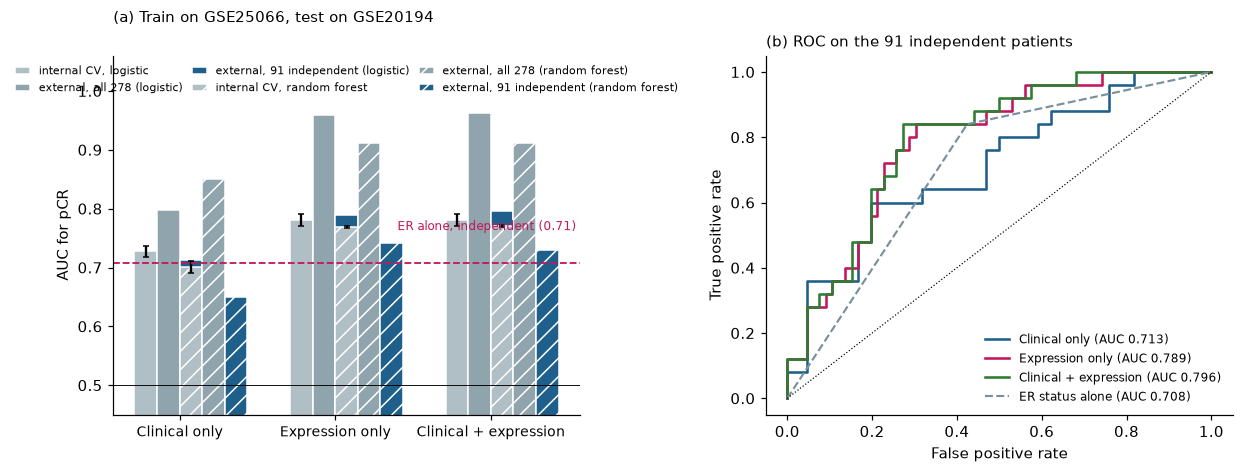

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axs[0]
sub = perf[(perf.Normalisation == "train-fitted")]
x = np.arange(len(FEATURESETS)); w = .145
for j, (kind, hatch) in enumerate((("logistic", ""), ("random forest", "//"))):
    s = sub[sub.Model == kind].set_index("Features").loc[FEATURESETS]
    ax.bar(x + (j*2-1.5)*w, s["Internal CV AUC"], w, yerr=s["Internal SD"], capsize=2,
           color="#B0BEC5", hatch=hatch, edgecolor="w", label=f"internal CV, {kind}")
    ax.bar(x + (j*2-0.5)*w, s["External AUC (all)"], w, color="#90A4AE", hatch=hatch,
           edgecolor="w", label=f"external, all 278 ({kind})")
    ax.bar(x + (j*2+0.5)*w, s["External AUC (independent)"], w, color="#1F5F8B", hatch=hatch,
           edgecolor="w", label=f"external, 91 independent ({kind})")
ER_IND = roc_auc_score(y[CTEST][IND], er_te[IND])
ax.axhline(ER_IND, color="#C2185B", ls="--", lw=1.2)
ax.text(len(FEATURESETS)-0.45, ER_EXT + .006, f"ER alone, independent ({ER_IND:.2f})",
        fontsize=8, ha="right", color="#C2185B")
ax.axhline(.5, color="k", lw=.6)
ax.set_xticks(x, FEATURESETS, fontsize=9); ax.set_ylim(.45, 1.06)
ax.set_ylabel("AUC for pCR")
ax.legend(fontsize=7, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.0),
          columnspacing=.9, handlelength=1.4)
ax.set_title(f"(a) Train on {CTRAIN}, test on {CTEST}", fontsize=9.5, loc="left", pad=22)

ax = axs[1]
for fs in FEATURESETS:
    _, pe = curves[("train-fitted", fs, "logistic")]
    fpr, tpr, _ = roc_curve(y[CTEST][IND], pe[IND])
    ax.plot(fpr, tpr, color=COL[fs], lw=1.7,
            label=f"{fs} (AUC {roc_auc_score(y[CTEST][IND], pe[IND]):.3f})")
fpr, tpr, _ = roc_curve(y[CTEST][IND], er_te[IND])
ax.plot(fpr, tpr, color=COL["ER status alone"], lw=1.4, ls="--",
        label=f"ER status alone (AUC {roc_auc_score(y[CTEST][IND], er_te[IND]):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(fontsize=8, frameon=False, loc="lower right")
ax.set_title(f"(b) ROC on the 91 independent patients", fontsize=9.5, loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig3_internal_vs_external.png"); plt.show()

### Figure 3 --- the normalisation choice

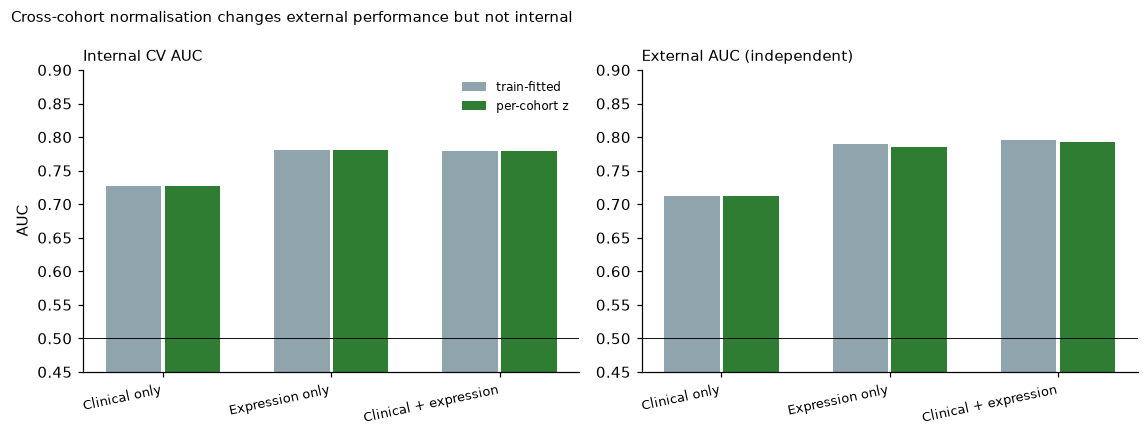

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, metric in zip(axs, ("Internal CV AUC", "External AUC (independent)")):
    for j, scheme in enumerate(("train-fitted", "per-cohort z")):
        s = perf[(perf.Normalisation == scheme) & (perf.Model == "logistic")].set_index("Features").loc[FEATURESETS]
        ax.bar(np.arange(len(FEATURESETS)) + (j-.5)*.35, s[metric], .33,
               color=["#90A4AE", "#2E7D32"][j], label=scheme)
    ax.axhline(.5, color="k", lw=.6); ax.set_ylim(.45, .9)
    ax.set_xticks(range(len(FEATURESETS)), FEATURESETS, fontsize=8.5, rotation=12, ha="right")
    ax.set_title(metric, fontsize=9.5, loc="left")
axs[0].set_ylabel("AUC"); axs[0].legend(fontsize=8, frameon=False)
fig.suptitle("Cross-cohort normalisation changes external performance but not internal",
             fontsize=10, x=.01, ha="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig4_normalisation.png"); plt.show()

## 6. Does expression add anything beyond receptor status?
Restricting to ER-positive and ER-negative patients separately removes the receptor signal and
asks whether the expression model still discriminates within each stratum.

In [12]:
strat = []
for scheme in ("train-fitted",):
    for fs in FEATURESETS:
        _, pe = curves[(scheme, fs, "logistic")]
        for name, mask in (("ER-negative", clin[CTEST].ER.eq(0).values & IND),
                           ("ER-positive", clin[CTEST].ER.eq(1).values & IND)):
            if mask.sum() < 20 or len(np.unique(y[CTEST][mask])) < 2:
                continue
            strat.append({"Features": fs, "Stratum": name, "n": int(mask.sum()),
                          "pCR n": int(y[CTEST][mask].sum()),
                          "AUC": roc_auc_score(y[CTEST][mask], pe[mask])})
strat = pd.DataFrame(strat)
strat.round(3).to_csv(f"{RES}/Table5_stratified_external.csv", index=False)
strat.round(3)

,Features,Stratum,n,pCR n,AUC
0,Clinical only,ER-negative,49,21,0.594
1,Clinical only,ER-positive,42,4,0.447
2,Expression only,ER-negative,49,21,0.714
3,Expression only,ER-positive,42,4,0.842
4,Clinical + expression,ER-negative,49,21,0.723
5,Clinical + expression,ER-positive,42,4,0.849


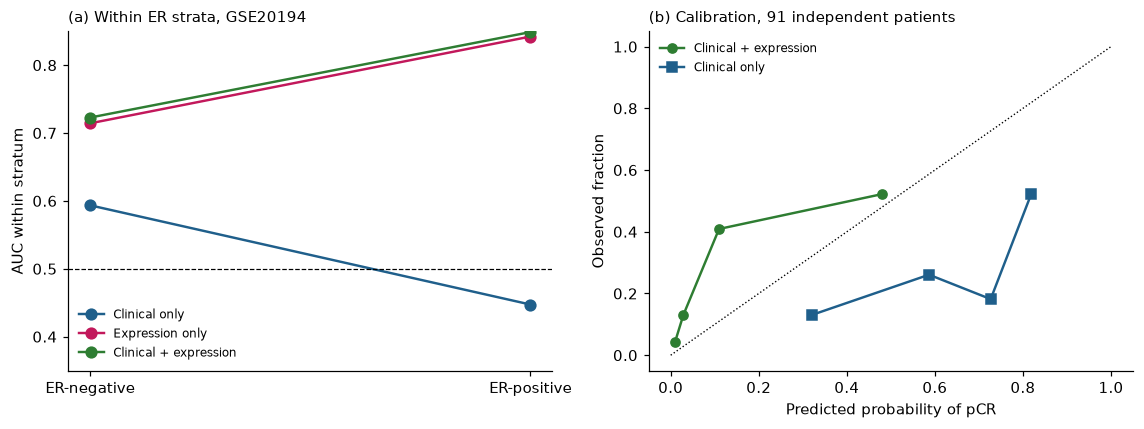

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
ax = axs[0]
for fs in FEATURESETS:
    s = strat[strat.Features == fs]
    ax.plot(s.Stratum, s.AUC, "o-", color=COL[fs], label=fs, lw=1.6, ms=7)
ax.axhline(.5, color="k", ls="--", lw=.8)
ax.set_ylabel("AUC within stratum"); ax.set_ylim(.35, .85)
ax.legend(fontsize=8, frameon=False)
ax.set_title(f"(a) Within ER strata, {CTEST}", fontsize=9.5, loc="left")

ax = axs[1]
_, pe = curves[("train-fitted", "Clinical + expression", "logistic")]
frac, mean_pred = calibration_curve(y[CTEST][IND], pe[IND], n_bins=4, strategy="quantile")
ax.plot(mean_pred, frac, "o-", color="#2E7D32", lw=1.6, label="Clinical + expression")
_, pe2 = curves[("train-fitted", "Clinical only", "logistic")]
frac2, mp2 = calibration_curve(y[CTEST][IND], pe2[IND], n_bins=4, strategy="quantile")
ax.plot(mp2, frac2, "s-", color="#1F5F8B", lw=1.6, label="Clinical only")
ax.plot([0, 1], [0, 1], "k:", lw=.9)
ax.set_xlabel("Predicted probability of pCR"); ax.set_ylabel("Observed fraction")
ax.legend(fontsize=8, frameon=False)
ax.set_title("(b) Calibration, 91 independent patients", fontsize=9.5, loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig5_strata_calibration.png"); plt.show()

## 7. Key numbers

In [14]:
key = {"train cohort": f"{CTRAIN}: {len(y[CTRAIN])} patients, {int(y[CTRAIN].sum())} pCR "
                       f"({100*y[CTRAIN].mean():.0f}%)",
       "test cohort": f"{CTEST}: {len(y[CTEST])} patients, {int(y[CTEST].sum())} pCR "
                      f"({100*y[CTEST].mean():.0f}%)",
       "shared probes": f"{len(probes):,}", "panel": f"{len(panel):,}",
       "pCR rate ER-neg vs ER-pos (train)":
           f"{100*y[CTRAIN][clin[CTRAIN].ER.eq(0).values].mean():.0f}% vs "
           f"{100*y[CTRAIN][clin[CTRAIN].ER.eq(1).values].mean():.0f}%",
       "overlap: duplicated test samples": f"{int(is_dup.sum())}/{len(is_dup)} ({100*is_dup.mean():.0f}%)",
       "independent test patients": f"{int(IND.sum())} ({int(y[CTEST][IND].sum())} pCR)",
       "ER alone AUC internal / external(all) / external(independent)":
           f"{ER_INT:.3f} / {ER_EXT:.3f} / {roc_auc_score(y[CTEST][IND], er_te[IND]):.3f}"}
for _, r in perf[perf.Normalisation == "train-fitted"].iterrows():
    key[f"{r.Features} | {r.Model}"] = (f"internal {r['Internal CV AUC']:.3f} ± {r['Internal SD']:.3f} "
                                        f"| ext-all {r['External AUC (all)']:.3f} "
                                        f"| ext-indep {r['External AUC (independent)']:.3f}")
for _, r in perf[perf.Normalisation == "per-cohort z"].iterrows():
    if r.Model == "logistic":
        key[f"[per-cohort z] {r.Features} | logistic"] = (f"internal {r['Internal CV AUC']:.3f} "
                                                          f"| ext-indep {r['External AUC (independent)']:.3f}")
for _, r in strat.iterrows():
    key[f"stratified {r.Stratum} | {r.Features}"] = f"AUC {r.AUC:.3f} (n={r.n}, {r['pCR n']} pCR)"
json.dump(key, open(f"{RES}/key_numbers.json", "w"), indent=1, default=str)
for k, v in key.items():
    print(f"{k:54s} {v}")

train cohort                                           GSE25066: 488 patients, 99 pCR (20%)
test cohort                                            GSE20194: 278 patients, 56 pCR (20%)
shared probes                                          22,283
panel                                                  3,000
pCR rate ER-neg vs ER-pos (train)                      35% vs 11%
overlap: duplicated test samples                       187/278 (67%)
independent test patients                              91 (25 pCR)
ER alone AUC internal / external(all) / external(independent) 0.679 / 0.758 / 0.708
Clinical only | logistic                               internal 0.727 ± 0.010 | ext-all 0.798 | ext-indep 0.713
Clinical only | random forest                          internal 0.701 ± 0.010 | ext-all 0.851 | ext-indep 0.650
Expression only | logistic                             internal 0.780 ± 0.010 | ext-all 0.959 | ext-indep 0.789
Expression only | random forest                        internal 0.769 ±

In [15]:
for d_ in (FIG, RES):
    for f in sorted(os.listdir(d_)):
        print(f"{d_}/{f}  ({os.path.getsize(os.path.join(d_, f))/1024:.0f} KB)")

./figures/Fig1_cohorts.png  (167 KB)
./figures/Fig2_cohort_overlap.png  (114 KB)
./figures/Fig3_internal_vs_external.png  (246 KB)
./figures/Fig4_normalisation.png  (138 KB)
./figures/Fig5_strata_calibration.png  (203 KB)
./results/Table1_cohorts.csv  (0 KB)
./results/Table2_univariate_clinical.csv  (1 KB)
./results/Table3_overlap.csv  (8 KB)
./results/Table4_performance.csv  (1 KB)
./results/Table5_stratified_external.csv  (0 KB)
./results/key_numbers.json  (2 KB)
